# Optimización del MLP para probabilidad de incumplimiento (PD)

Este notebook realiza la prueba de tasa de aprendizaje, una búsqueda aleatoria inicial, refinamiento y análisis de robustez para un MLP binario. Reutiliza el split temporal y el preprocesador del repositorio. Durante la optimización solo se emplean entrenamiento 2007–2012 y validación 2013; prueba 2014 y complementario 2015 quedan reservados para una etapa posterior.

**Estado del entorno:** requiere `data/raw/loan/loan.csv`. Los resultados no se deben presentar hasta ejecutar todas las celdas con el archivo fuente y guardar los artefactos.


## Método y justificación

Se usa **random search** porque en espacios de muchas dimensiones suele explorar mejor que un grid con el mismo presupuesto: cada ensayo puede probar valores distintos de los hiperparámetros influyentes, sin multiplicar todas las combinaciones. La tasa de aprendizaje y las penalizaciones se muestrean en escala logarítmica porque interesan órdenes de magnitud. La fase de refinamiento concentra una segunda búsqueda alrededor de las diez mejores configuraciones iniciales. El presupuesto fijado para esta ejecución es de 150 ensayos iniciales y 30 de refinamiento, según el ajuste solicitado; es mayor que el presupuesto orientativo del documento original. Esto amplía la exploración y aumenta el costo computacional. Con parada temprana, `EarlyStopping` limita el costo. Se prefiere a optimización bayesiana en esta primera versión por simplicidad y facilidad de explicación, no porque se espere que siempre sea inferior. Para la exploración, preparación y evaluación se toma como referencia adicional Géron (2019, caps. 2–4); para MLP, ajuste de hiperparámetros, optimización y regularización, los capítulos 10–11. Estas referencias metodológicas no garantizan que una red neuronal supere modelos tabulares de referencia.

El espacio conjunto incluye profundidad y ancho, activación, optimizador, tasa de aprendizaje, dropout, tipo e intensidad de penalización y tamaño de lote. Esto deja que sus interacciones aparezcan en los ensayos. Las decisiones se seleccionan por AUC-ROC en 2013 y se desempatan por menor log-loss.

**Limitaciones:** 2013 se usa tanto para parada temprana como para selección; por ello no es una estimación imparcial del desempeño final. El espacio acotado no garantiza el óptimo global. Se utiliza una partición temporal fija, no validación cruzada aleatoria. La robustez se comprueba repitiendo las mejores configuraciones con cinco semillas. No se compara con optimización bayesiana.

Referencias metodológicas: Bergstra y Bengio (2012), *Random Search for Hyper-Parameter Optimization*, JMLR 13(10), 281–305; Srivastava et al. (2014), *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*, JMLR 15(56), 1929–1958; Gorishniy et al. (2021), *Revisiting Deep Learning Models for Tabular Data*, NeurIPS 34; Kadra et al. (2021), *Well-tuned Simple Nets Excel on Tabular Datasets*, NeurIPS 34. Se citan trabajos sobre el método y regularización; no se atribuye a ellos una garantía de que la red vaya a superar modelos tabulares de referencia.


## 1. Reconocimiento del repositorio y contrato de datos

Se reutilizan `credit_risk.data.prepare_data.preparar_matrices_pd` y `credit_risk.data.preprocessing.construir_preprocesador`. El split existente es: entrenamiento 2007–2012, validación 2013, prueba 2014 y conjunto complementario 2015. El preprocesador ajusta imputación, escalado y one-hot solo con entrenamiento y produce 44 columnas. No se altera el código del split ni del preprocesamiento.

El README de datos documenta 90.347, 73.194, 74.154 y 30.835 filas respectivamente. La matriz guardada de baseline no aparece en este repositorio; esta etapa usa directamente la misma función de preparación existente y no redefine la regresión logística. La limitación temporal declarada es que los resultados finales de créditos podrían haberse observado después de originarlos.


In [1]:
from pathlib import Path
import sys, os, json, random, platform, time, math, warnings
from datetime import datetime, timezone

ROOT = Path.cwd()
if not (ROOT / "configs" / "default.yaml").exists():
    ROOT = Path.cwd().parent
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    def display(value): print(value)
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from credit_risk.data.prepare_data import preparar_matrices_pd

SEED = 202602
N_TRIALS_PHASE_1 = 150  # presupuesto solicitado por el usuario
N_TRIALS_PHASE_2 = 30  # presupuesto solicitado por el usuario
ROBUSTNESS_SEEDS = [11, 23, 37, 41, 53]
MAX_EPOCHS = 100
PATIENCE = 8
BATCH_CHOICES = [256, 512, 1024, 2048]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
if DEVICE.type == "cpu": torch.set_num_threads(min(4, os.cpu_count() or 1))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scipy": scipy.__version__, "sklearn": sklearn.__version__, "torch": torch.__version__,
       "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       "seed": SEED, "started_utc": datetime.now(timezone.utc).isoformat()})
if not (ROOT / "data/raw/loan/loan.csv").exists():
    raise FileNotFoundError(f"Falta el dataset requerido: {ROOT / 'data/raw/loan/loan.csv'}")


{'python': '3.11.9', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scipy': '1.14.1', 'sklearn': '1.5.2', 'torch': '2.5.1', 'device': 'cpu', 'gpu': None, 'seed': 202602, 'started_utc': '2026-10-27T03:11:57.003948+00:00'}


In [2]:
# Carga y transforma una sola vez con el pipeline existente.
# Aunque las cuatro particiones se preparan, las siguientes celdas solo modelan train/validation.
X, y, preprocessor = preparar_matrices_pd()

expected_rows = {"train": 90347, "validation": 73194, "test": 74154, "supplementary_2015": 30835}
partition_summary = []
for split in ["train", "validation", "test", "supplementary_2015"]:
    labels = np.asarray(y[split], dtype=np.int64)
    partition_summary.append({"split": split, "rows": len(labels), "features": X[split].shape[1],
                              "bad_rate": float(labels.mean()) if len(labels) else np.nan,
                              "documented_rows": expected_rows[split],
                              "matches_documentation": len(labels) == expected_rows[split]})
display(pd.DataFrame(partition_summary))

if X["train"].shape[1] != 44:
    raise ValueError(f"Se esperaban 44 columnas procesadas y se recibieron {X['train'].shape[1]}.")
if X["train"].shape[0] != 90347 or X["validation"].shape[0] != 73194:
    raise ValueError("Los tamaños train/validation no coinciden con el README; detenga la búsqueda y revise el dataset.")
if set(np.unique(y["train"])) != {0, 1} or set(np.unique(y["validation"])) != {0, 1}:
    raise ValueError("Train y validation deben contener las clases 0 y 1.")

# Matrices compactas en float32; no se usa test ni 2015 para escoger parámetros.
def dense_float32(matrix):
    return matrix.toarray().astype(np.float32, copy=False) if hasattr(matrix, "toarray") else np.asarray(matrix, dtype=np.float32)
X_train_np = dense_float32(X["train"])
X_val_np = dense_float32(X["validation"])
y_train_np = np.asarray(y["train"], dtype=np.float32)
y_val_np = np.asarray(y["validation"], dtype=np.float32)
print("Tasa de incumplimiento train:", y_train_np.mean(), "validation:", y_val_np.mean())
print("Class weighting desactivado para no cambiar la prevalencia efectiva de la pérdida.")


1. Cargando dataset...
2. Construyendo variable objetivo...
3. Preparando fechas...
4. Asignando particiones...
5. Calculando antigüedad crediticia...
6. Ajustando preprocesador...

RESULTADOS DEL PREPROCESAMIENTO
train: 90347 registros, 44 características
validation: 73194 registros, 44 características
test: 74154 registros, 44 características
supplementary_2015: 30835 registros, 44 características
                split   rows  ...  documented_rows  matches_documentation
0               train  90347  ...            90347                   True
1          validation  73194  ...            73194                   True
2                test  74154  ...            74154                   True
3  supplementary_2015  30835  ...            30835                   True

[4 rows x 6 columns]
Tasa de incumplimiento train: 0.16302699 validation: 0.22949968
Class weighting desactivado para no cambiar la prevalencia efectiva de la pérdida.


## 2. Métricas para selección

La clase positiva es incumplimiento (`1`). AUC mide ordenamiento; `Gini = 2 AUC − 1`; KS es la máxima distancia entre las distribuciones acumuladas de malos y buenos (`max |TPR−FPR|`). Brier y log-loss evalúan probabilidades, no solo ordenamiento. La selección usa AUC en validación y, en empate numérico, menor log-loss.


In [3]:
def binary_metrics(y_true, probability):
    p = np.clip(np.asarray(probability, dtype=float), 1e-7, 1 - 1e-7)
    fpr, tpr, _ = roc_curve(np.asarray(y_true, dtype=int), p)
    auc = float(roc_auc_score(y_true, p))
    return {"auc": auc, "gini": 2 * auc - 1,
            "ks": float(np.max(np.abs(tpr - fpr))),
            "brier": float(brier_score_loss(y_true, p)),
            "log_loss": float(log_loss(y_true, p, labels=[0, 1]))}


## 3. Prueba de tasa de aprendizaje

Se recorre exponencialmente de `1e-5` a `1` durante una época, actualizando la tasa de aprendizaje en cada minibatch. Es un diagnóstico aproximado: la pérdida al principio puede reflejar inicialización y ruido de minibatch; no se selecciona directamente una configuración con este gráfico. La búsqueda confirmará o ajustará el intervalo predefinido `[1e-4, 1e-2]`.


In [4]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

class PDNet(nn.Module):
    def __init__(self, input_dim, n_layers, width, activation, dropout):
        super().__init__()
        n_layers, width = int(n_layers), int(width)
        act = nn.ReLU if activation == "relu" else nn.Tanh
        blocks, previous = [], input_dim
        for _ in range(n_layers):
            blocks.extend([nn.Linear(previous, width), act()])
            if dropout > 0:
                blocks.append(nn.Dropout(dropout))
            previous = width
        self.hidden = nn.Sequential(*blocks)
        self.output = nn.Linear(previous, 1)
    def forward(self, x):
        return self.output(self.hidden(x)).squeeze(-1)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_optimizer(model, config):
    name, lr = config["optimizer"], config["learning_rate"]
    if name == "adam": return torch.optim.Adam(model.parameters(), lr=lr)
    if name == "nadam": return torch.optim.NAdam(model.parameters(), lr=lr)
    if name == "sgd_momentum": return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    raise ValueError(f"Optimizador no reconocido: {name}")

def weight_penalty(model, config):
    weights = [p for name, p in model.named_parameters() if "weight" in name]
    value = torch.zeros((), device=DEVICE)
    if config["reg_type"] in ("l1", "elastic_net"):
        value = value + config["l1"] * sum(w.abs().sum() for w in weights)
    if config["reg_type"] in ("l2", "elastic_net"):
        value = value + config["l2"] * sum((w ** 2).sum() for w in weights) / 2
    return value

def make_loader(x, y, batch_size, seed, shuffle=True):
    generator = torch.Generator().manual_seed(int(seed))
    ds = TensorDataset(torch.from_numpy(x), torch.from_numpy(y))
    return DataLoader(ds, batch_size=int(batch_size), shuffle=shuffle, generator=generator)

def fit_config(config, seed, return_model=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    model = PDNet(X_train_np.shape[1], config["n_layers"], config["width"], config["activation"], config["dropout"]).to(DEVICE)
    optimizer = make_optimizer(model, config)
    loss_fn = nn.BCEWithLogitsLoss()
    train_loader = make_loader(X_train_np, y_train_np, config["batch_size"], seed)
    x_val_t = torch.from_numpy(X_val_np).to(DEVICE)
    y_val_t = torch.from_numpy(y_val_np).to(DEVICE)
    best_loss, best_state, best_epoch, stale = float("inf"), None, 0, 0
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb) + weight_penalty(model, config)
            if not torch.isfinite(loss): raise FloatingPointError("loss no finita")
            loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = float(loss_fn(model(x_val_t), y_val_t).item())
        if not math.isfinite(val_loss): raise FloatingPointError("val_loss no finita")
        if val_loss < best_loss - 1e-5:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE: break
    if best_state is None: raise FloatingPointError("No se obtuvo un estado finito")
    model.load_state_dict(best_state); model.to(DEVICE); model.eval()
    with torch.no_grad():
        val_probability = torch.sigmoid(model(x_val_t)).detach().cpu().numpy()
    result = {**binary_metrics(y_val_np, val_probability), "epochs": best_epoch,
              "seconds": time.perf_counter() - started, "parameters": count_parameters(model)}
    return (model, result) if return_model else result

# Verifica que las combinaciones de optimizador estén soportadas por la versión local.
assert hasattr(torch.optim, "NAdam"), "La búsqueda requiere PyTorch con torch.optim.NAdam"


<string>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
Mínimo de la pérdida de minibatch: {'learning_rate': 0.07305271542664453, 'loss': 0.39675793051719666}


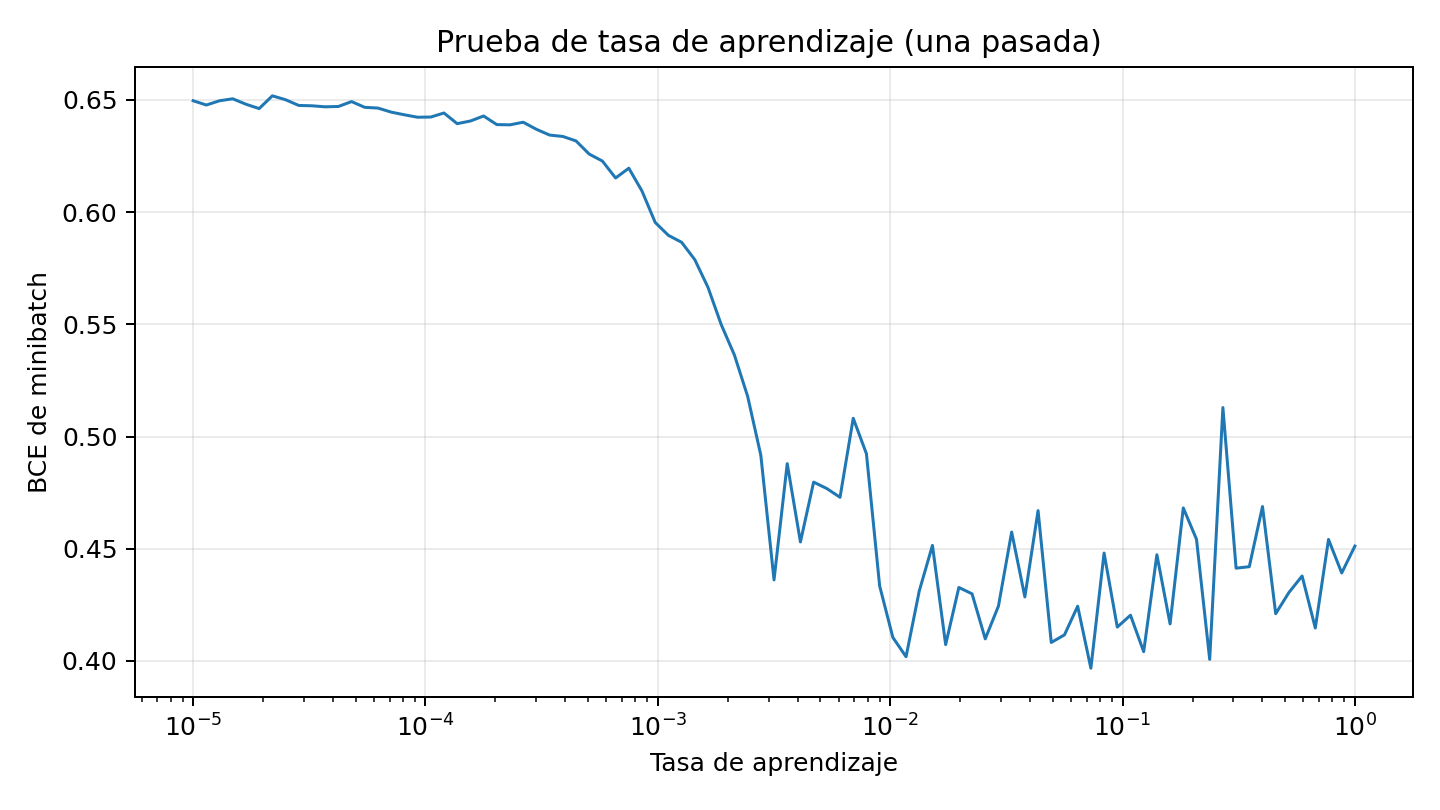

In [5]:
# Prueba LR: inicialización independiente; entrenamiento de una época y aumento exponencial.
def learning_rate_range_test(start=1e-5, end=1.0):
    config = {"n_layers": 2, "width": 64, "activation": "relu", "dropout": 0.0,
              "optimizer": "adam", "learning_rate": start, "batch_size": 1024,
              "reg_type": "none", "l1": 0.0, "l2": 0.0}
    torch.manual_seed(SEED)
    model = PDNet(X_train_np.shape[1], 2, 64, "relu", 0.0).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=start)
    loader = make_loader(X_train_np, y_train_np, 1024, SEED)
    rates, losses = [], []
    total = len(loader)
    for i, (xb, yb) in enumerate(loader):
        lr = start * (end / start) ** (i / max(total - 1, 1))
        for group in optimizer.param_groups: group["lr"] = lr
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.binary_cross_entropy_with_logits(model(xb), yb)
        if not torch.isfinite(loss): break
        loss.backward(); optimizer.step()
        rates.append(lr); losses.append(float(loss.detach().cpu()))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(rates, losses, linewidth=1.2)
    ax.set_xscale("log"); ax.set_xlabel("Tasa de aprendizaje"); ax.set_ylabel("BCE de minibatch")
    ax.set_title("Prueba de tasa de aprendizaje (una pasada) "); ax.grid(alpha=.25)
    lr_out = ROOT / "reports" / "pd_hyperparameter_search"
    lr_out.mkdir(parents=True, exist_ok=True)
    fig.tight_layout(); fig.savefig(lr_out / "prueba_tasa_aprendizaje.png", dpi=180)
    plt.show()
    return pd.DataFrame({"learning_rate": rates, "loss": losses})

lr_curve = learning_rate_range_test()
lr_curve.to_csv(ROOT / "reports" / "pd_hyperparameter_search" / "prueba_tasa_aprendizaje.csv", index=False)
print("Mínimo de la pérdida de minibatch:", lr_curve.loc[lr_curve.loss.idxmin()].to_dict())


La curva observada cae con fuerza entre aproximadamente `1e-3` y `1e-2`; por encima de `1e-2` se vuelve ruidosa entre minibatches y no muestra una reducción estable. Por ello se conserva `[1e-4, 1e-2]` como rango conservador: contiene la zona de descenso y evita escoger tasas altas a partir del mínimo aislado y ruidoso. La tasa elegida finalmente se decidirá por AUC y log-loss en validación, no por esta prueba de una pasada.


## 4. Fase 1: random search (150 ensayos)

El presupuesto configurado es de 150 ensayos. Los valores fijos de parada temprana son paciencia 8, máximo 100 épocas y restauración del mejor estado según BCE de validación. Los pesos no se reponderan. Cada ensayo escribe su fila en CSV incluso si falla; así un fallo numérico no interrumpe el presupuesto completo.


In [6]:
from scipy.stats import spearmanr

OUT = ROOT / "reports" / "pd_hyperparameter_search"
OUT.mkdir(parents=True, exist_ok=True)
TRIALS_CSV = OUT / "ensayos.csv"
LR_BOUNDS = (1e-4, 1e-2)
WIDTHS = [16, 32, 64, 128, 256]
ACTIVATIONS = ["relu", "tanh"]
OPTIMIZERS = ["adam", "nadam", "sgd_momentum"]
REG_TYPES = ["none", "l1", "l2", "elastic_net"]


def log_uniform(rng, low, high):
    return float(np.exp(rng.uniform(np.log(low), np.log(high))))

def sample_phase1(rng):
    reg = str(rng.choice(REG_TYPES))
    return {"n_layers": int(rng.integers(1, 5)), "width": int(rng.choice(WIDTHS)),
            "activation": str(rng.choice(ACTIVATIONS)), "optimizer": str(rng.choice(OPTIMIZERS)),
            "learning_rate": log_uniform(rng, *LR_BOUNDS), "dropout": float(rng.uniform(0.0, 0.5)),
            "reg_type": reg, "l1": log_uniform(rng, 1e-6, 1e-3) if reg in ("l1", "elastic_net") else 0.0,
            "l2": log_uniform(rng, 1e-6, 1e-3) if reg in ("l2", "elastic_net") else 0.0,
            "batch_size": int(rng.choice(BATCH_CHOICES))}

def run_search(phase, n_trials, sampler, seed):
    rng = np.random.default_rng(seed)
    configs = [sampler(rng) for _ in range(n_trials)]
    prior = pd.read_csv(TRIALS_CSV) if TRIALS_CSV.exists() else pd.DataFrame()
    done = set(prior.loc[prior.phase == phase, "trial_id"].astype(int)) if len(prior) else set()
    rows = []
    for i, config in enumerate(configs, start=1):
        if i in done:
            continue
        record = {"phase": phase, "trial_id": i, "seed": seed, **config, "status": "ok", "error": ""}
        try:
            record.update(fit_config(config, seed))
        except Exception as exc:
            record.update({"auc": np.nan, "gini": np.nan, "ks": np.nan, "brier": np.nan,
                           "log_loss": np.nan, "epochs": np.nan, "seconds": np.nan,
                           "parameters": np.nan, "status": "failed", "error": repr(exc)[:500]})
        rows.append(record)
        pd.DataFrame(rows).to_csv(TRIALS_CSV, index=False) if not prior.empty else None
        existing = pd.concat([prior, pd.DataFrame(rows)], ignore_index=True) if not prior.empty else pd.DataFrame(rows)
        existing.to_csv(TRIALS_CSV, index=False)
        print(f"{phase} {i:02d}/{n_trials}: {record['status']} AUC={record.get('auc', np.nan):.5f} tiempo={record.get('seconds', np.nan):.1f}s", flush=True)
    all_rows = pd.read_csv(TRIALS_CSV)
    return all_rows[(all_rows.phase == phase) & (all_rows.status == "ok")].sort_values(["auc", "log_loss"], ascending=[False, True]).reset_index(drop=True)

phase1 = run_search("phase1", N_TRIALS_PHASE_1, sample_phase1, SEED + 1)
if len(phase1) < 10:
    raise RuntimeError("Menos de 10 ensayos válidos; revise fallos antes de refinar.")
display(phase1.head(10))


phase1 61/150: ok AUC=0.66186 tiempo=10.9s
phase1 62/150: ok AUC=0.67010 tiempo=10.4s
phase1 63/150: ok AUC=0.66582 tiempo=4.1s
phase1 64/150: ok AUC=0.66424 tiempo=2.8s
phase1 65/150: ok AUC=0.60867 tiempo=9.5s
phase1 66/150: ok AUC=0.67214 tiempo=5.4s
phase1 67/150: ok AUC=0.66609 tiempo=5.6s
phase1 68/150: ok AUC=0.66950 tiempo=3.9s
phase1 69/150: ok AUC=0.66737 tiempo=14.3s
phase1 70/150: ok AUC=0.66676 tiempo=5.1s
phase1 71/150: ok AUC=0.66435 tiempo=6.3s
phase1 72/150: ok AUC=0.66224 tiempo=13.6s
phase1 73/150: ok AUC=0.66172 tiempo=3.7s
phase1 74/150: ok AUC=0.65916 tiempo=12.2s
phase1 75/150: ok AUC=0.60271 tiempo=5.6s
phase1 76/150: ok AUC=0.54692 tiempo=22.6s
phase1 77/150: ok AUC=0.66334 tiempo=12.0s
phase1 78/150: ok AUC=0.67292 tiempo=4.0s
phase1 79/150: ok AUC=0.66051 tiempo=2.2s
phase1 80/150: ok AUC=0.66090 tiempo=6.3s
phase1 81/150: ok AUC=0.66058 tiempo=9.1s
phase1 82/150: ok AUC=0.65601 tiempo=13.0s
phase1 83/150: ok AUC=0.66726 tiempo=10.4s
phase1 84/150: ok AUC=0.6

## 5. Análisis de fase 1

Se inspeccionan relaciones entre hiperparámetros y AUC, además de una importancia exploratoria por correlación de rangos. Son asociaciones sobre los ensayos observados, no efectos causales.


<string>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
      phase  trial_id    seed  ...  log10_dropout  log10_l1  log10_l2
36   phase1        37  202603  ...      -0.784327 -4.715440 -5.947207
128  phase1       129  202603  ...      -0.842973 -5.641227       NaN
77   phase1        78  202603  ...      -0.477976 -5.383643       NaN
112  phase1       113  202603  ...      -1.063164       NaN -3.461857
65   phase1        66  202603  ...      -1.619317       NaN -4.966088
59   phase1        60  202603  ...      -0.466186       NaN -5.068077
96   phase1        97  202603  ...      -0.805438       NaN       NaN
13   phase1        14  202603  ...      -1.620511       NaN -3.195381
129  phase1       130  202603  ...      -0.872369       NaN -3.068269
101  phase1       102  202603  ...      -1.873296       NaN       NaN

[10 rows x 28 columns]
  hyperparameter  ...                                  mean_auc_by_level
0       n_layers  ...                         

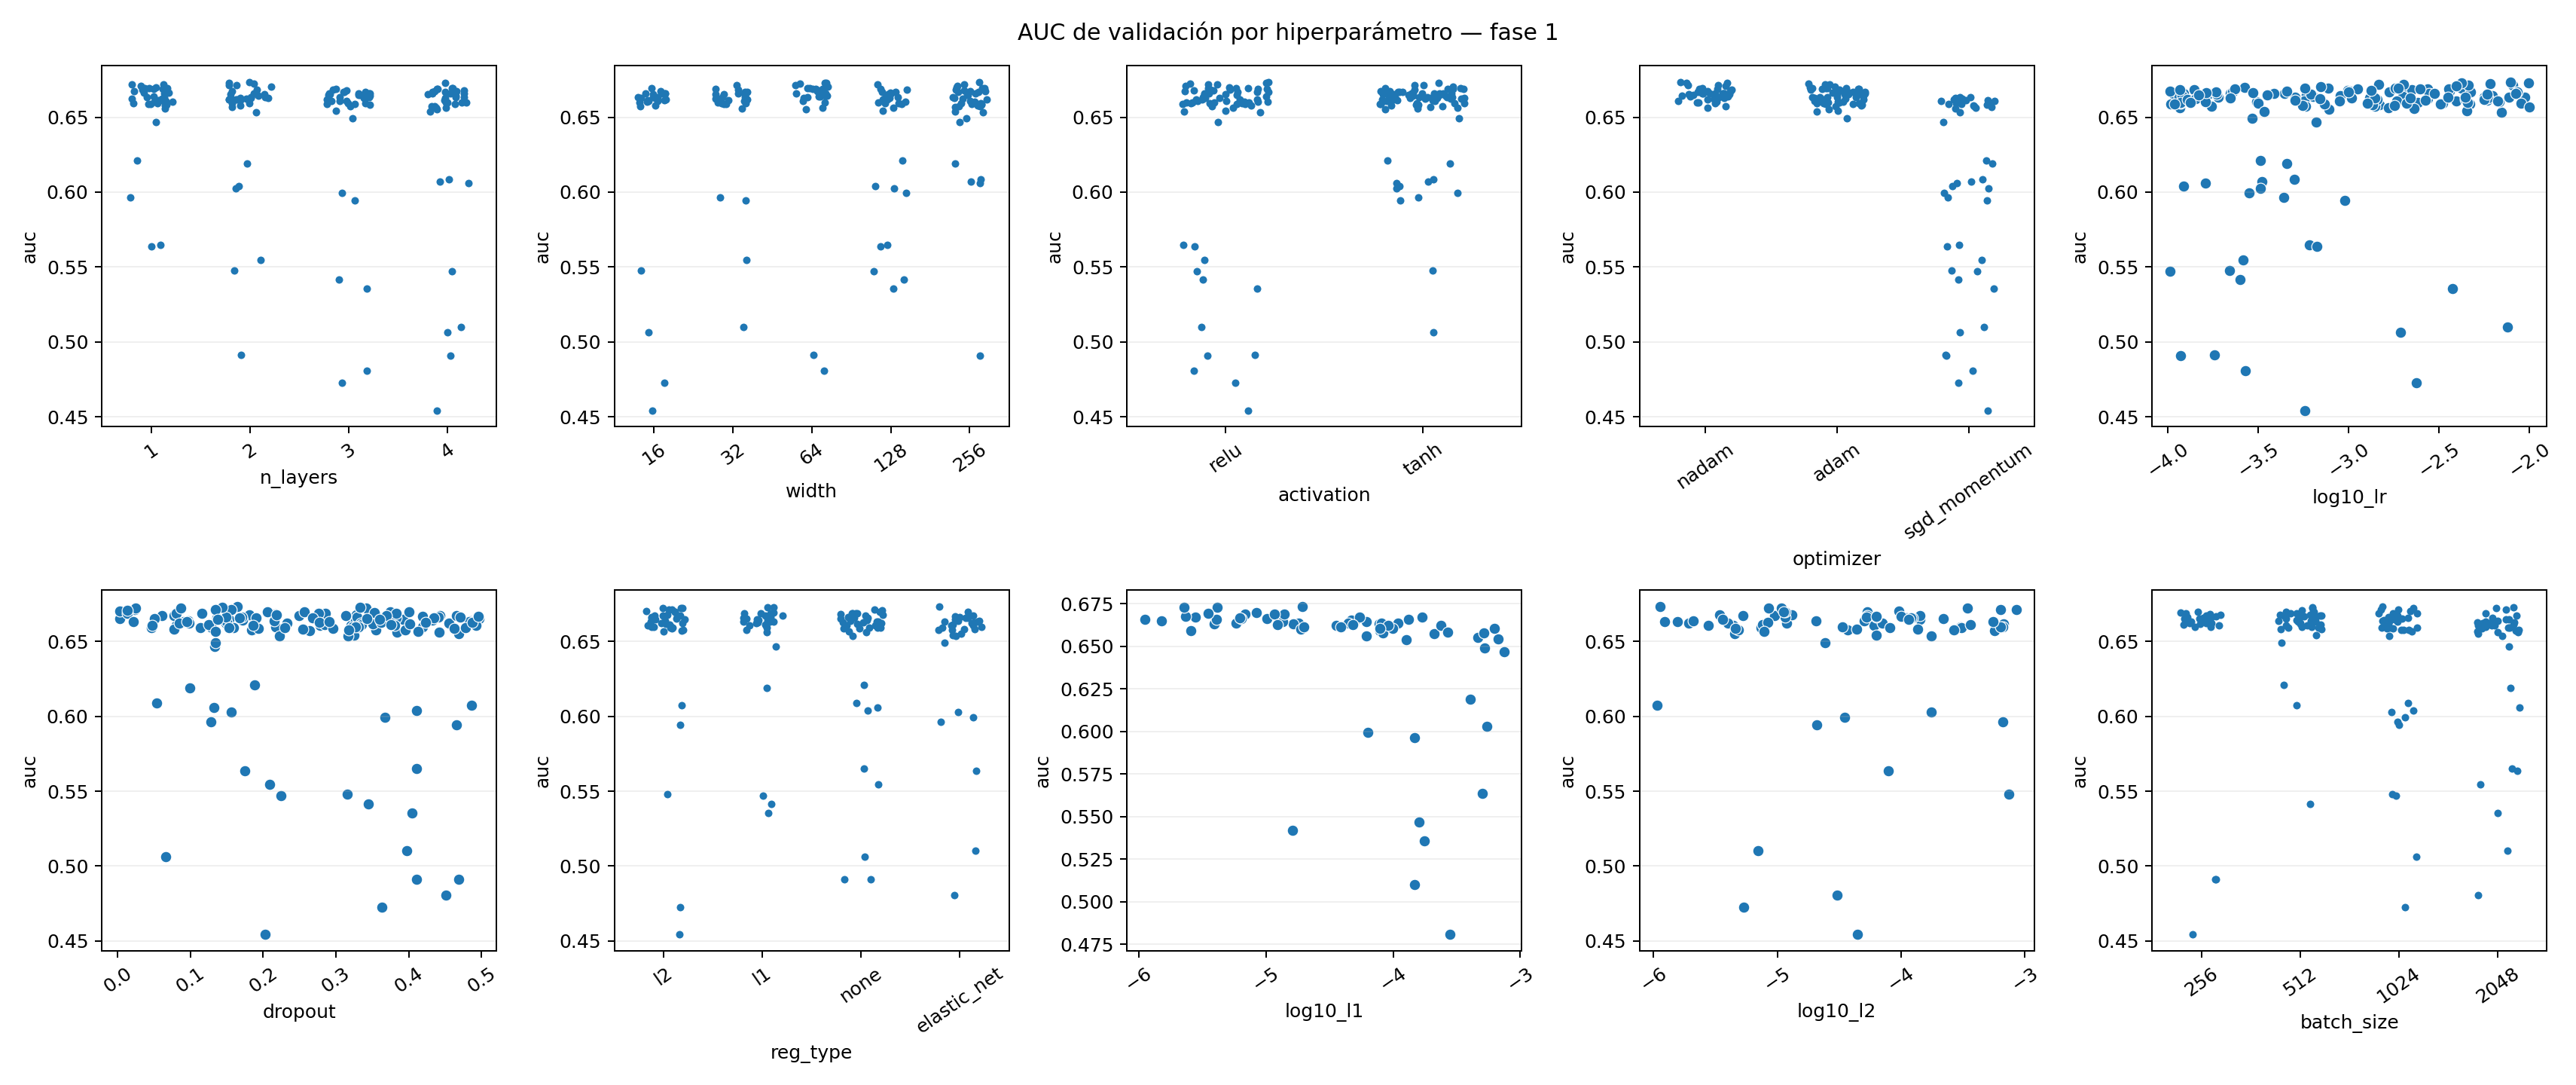

In [7]:
phase1_all = pd.read_csv(TRIALS_CSV).query("phase == 'phase1' and status == 'ok'").copy()
phase1_all["depth"] = phase1_all["n_layers"]
phase1_all["log10_lr"] = np.log10(phase1_all["learning_rate"])
phase1_all["log10_dropout"] = np.log10(phase1_all["dropout"].clip(lower=1e-5))
plot_columns = ["n_layers", "width", "activation", "optimizer", "log10_lr", "dropout", "reg_type", "log10_l1", "log10_l2", "batch_size"]
for col in ["l1", "l2"]:
    phase1_all[f"log10_{col}"] = np.log10(phase1_all[col].replace(0, np.nan))
fig, axes = plt.subplots(2, 5, figsize=(19, 8))
for ax, col in zip(axes.flat, plot_columns):
    if col.startswith("log10_") or col == "dropout":
        sns.scatterplot(data=phase1_all, x=col, y="auc", ax=ax, s=35)
    else:
        sns.stripplot(data=phase1_all, x=col, y="auc", ax=ax, jitter=.22, size=4)
    ax.tick_params(axis="x", rotation=35); ax.grid(axis="y", alpha=.2)
fig.suptitle("AUC de validación por hiperparámetro — fase 1")
fig.tight_layout(); fig.savefig(OUT / "fase1_auc_hiperparametros.png", dpi=180); plt.show()

importance = []
for col in ["n_layers", "width", "log10_lr", "dropout", "log10_l1", "log10_l2", "batch_size"]:
    valid = phase1_all[[col, "auc"]].dropna()
    if len(valid) > 2:
        rho, p = spearmanr(valid[col], valid.auc)
        importance.append({"hyperparameter": col, "spearman_rho": rho, "p_value_descriptive": p, "n": len(valid)})
for col in ["activation", "optimizer", "reg_type"]:
    means = phase1_all.groupby(col).auc.mean().sort_values(ascending=False)
    importance.append({"hyperparameter": col, "spearman_rho": np.nan, "p_value_descriptive": np.nan,
                       "n": len(phase1_all), "mean_auc_by_level": means.to_dict()})
importance_df = pd.DataFrame(importance)
importance_df.to_json(OUT / "fase1_importancia.json", orient="records", indent=2)
phase1_top10 = phase1_all.sort_values(["auc", "log_loss"], ascending=[False, True]).head(10)
phase1_top10.to_csv(OUT / "fase1_top10.csv", index=False)
display(phase1_top10)
display(importance_df)


## 6. Fase 2: refinamiento alrededor de las 10 mejores

La segunda fase restringe profundidad, ancho y categorías a valores frecuentes entre los diez mejores ensayos y sus vecinos plausibles; restringe tasa de aprendizaje a los límites observados en ese grupo, ampliados por un factor de 10 y recortados al intervalo aprobado por la prueba LR. Dropout se estrecha con cuantiles. Se realizan 20 nuevos ensayos aleatorios y se guardan junto con la fase 1.


In [8]:
def refine_sampler(top10):
    rows = top10.to_dict("records")
    depths = sorted(set(int(r["n_layers"]) for r in rows))
    dmin, dmax = max(1, min(depths) - 1), min(4, max(depths) + 1)
    width_counts = pd.Series([int(r["width"]) for r in rows]).value_counts()
    top_widths = list(width_counts.index[:2])
    width_idx = sorted(set(WIDTHS.index(w) for w in top_widths))
    neighbor_idx = set(width_idx)
    for idx in width_idx: neighbor_idx.update([max(0, idx - 1), min(len(WIDTHS)-1, idx + 1)])
    refined_widths = [WIDTHS[i] for i in sorted(neighbor_idx)]
    def top_levels(key, n=2):
        counts = pd.Series([r[key] for r in rows]).value_counts()
        return list(counts.index[:n])
    def refined_log_bounds(values, default=(1e-6, 1e-3)):
        positive = np.asarray([float(v) for v in values if float(v) > 0], dtype=float)
        if len(positive) == 0:
            return [float(default[0]), float(default[1])]
        low, high = np.quantile(np.log(positive), [.1, .9])
        low, high = float(np.exp(low)), float(np.exp(high))
        if high <= low:
            center = low
            low, high = center / np.sqrt(10), center * np.sqrt(10)
        low, high = max(default[0], low), min(default[1], high)
        if high <= low:
            center = float(np.clip(np.exp(np.mean(np.log(positive))), *default))
            low, high = max(default[0], center / np.sqrt(10)), min(default[1], center * np.sqrt(10))
        return [low, high]
    lr_vals = np.array([float(r["learning_rate"]) for r in rows])
    lr_low, lr_high = np.quantile(lr_vals, [.1, .9]).tolist()
    drop_vals = np.array([float(r["dropout"]) for r in rows])
    drop_low, drop_high = np.quantile(drop_vals, [.1, .9]).tolist()
    l1_bounds = refined_log_bounds([r["l1"] for r in rows])
    l2_bounds = refined_log_bounds([r["l2"] for r in rows])
    return {"layer_bounds": [dmin, dmax], "widths": refined_widths,
            "activations": top_levels("activation"), "optimizers": top_levels("optimizer"),
            "reg_types": top_levels("reg_type"), "batches": top_levels("batch_size"),
            "learning_rate_bounds": [float(lr_low), float(lr_high)],
            "dropout_bounds": [float(drop_low), float(drop_high)],
            "l1_bounds": l1_bounds, "l2_bounds": l2_bounds,
            "refinement_rule": "q10-q90 de las 10 mejores; log-cuántiles para LR y penalizaciones; categorías top-2; ancho con vecinos. Profundidad se amplía un nivel, acotado a 1-4."}

refined_space = refine_sampler(phase1.head(10))
print(json.dumps(refined_space, indent=2))
(OUT / "rangos_refinamiento.json").write_text(json.dumps(refined_space, indent=2), encoding="utf-8")

def sample_phase2(rng):
    reg = str(rng.choice(refined_space["reg_types"]))
    return {"n_layers": int(rng.integers(refined_space["layer_bounds"][0], refined_space["layer_bounds"][1] + 1)),
            "width": int(rng.choice(refined_space["widths"])),
            "activation": str(rng.choice(refined_space["activations"])),
            "optimizer": str(rng.choice(refined_space["optimizers"])),
            "learning_rate": log_uniform(rng, *refined_space["learning_rate_bounds"]),
            "dropout": float(rng.uniform(*refined_space["dropout_bounds"])),
            "reg_type": reg,
            "l1": log_uniform(rng, *refined_space["l1_bounds"]) if reg in ("l1", "elastic_net") else 0.0,
            "l2": log_uniform(rng, *refined_space["l2_bounds"]) if reg in ("l2", "elastic_net") else 0.0,
            "batch_size": int(rng.choice(refined_space["batches"]))}

phase2 = run_search("phase2", N_TRIALS_PHASE_2, sample_phase2, SEED + 2)
all_valid = pd.read_csv(TRIALS_CSV).query("status == 'ok'").sort_values(["auc", "log_loss"], ascending=[False, True])
phase2_top10 = all_valid.head(10)
phase2_top10.to_csv(OUT / "top10_ensayos.csv", index=False)
display(phase2_top10)


{
  "layer_bounds": [
    1,
    4
  ],
  "widths": [
    32,
    64,
    128,
    256
  ],
  "activations": [
    "relu",
    "tanh"
  ],
  "optimizers": [
    "nadam",
    "adam"
  ],
  "reg_types": [
    "l2",
    "l1"
  ],
  "batches": [
    1024,
    512
  ],
  "learning_rate_bounds": [
    0.00138339064087162,
    0.008297424966648639
  ],
  "dropout_bounds": [
    0.02290284798737143,
    0.3335937491721943
  ],
  "l1_bounds": [
    2.572110625516243e-06,
    1.4155300479086126e-05
  ],
  "l2_bounds": [
    3.1071195958512727e-06,
    0.0007382020542544482
  ],
  "refinement_rule": "q10-q90 de las 10 mejores; log-cu\u00e1ntiles para LR y penalizaciones; categor\u00edas top-2; ancho con vecinos. Profundidad se ampl\u00eda un nivel, acotado a 1-4."
}
phase2 01/30: ok AUC=0.66265 tiempo=8.4s
phase2 02/30: ok AUC=0.67002 tiempo=9.7s
phase2 03/30: ok AUC=0.65992 tiempo=6.7s
phase2 04/30: ok AUC=0.66786 tiempo=10.3s
phase2 05/30: ok AUC=0.66575 tiempo=11.2s
phase2 06/30: ok AUC=0.6671

## 7. Robustez de las mejores configuraciones

Se toman hasta cinco configuraciones distintas de mayor AUC de las dos fases y se repiten con cinco semillas fijas en entrenamiento/validación. La ganadora se elige por media de AUC. Si una candidata queda a menos de una desviación estándar de la mejor media, se prefiere la que tenga menos parámetros entrenables. El conjunto de prueba no participa.


In [9]:
def config_key(row):
    keys = ["n_layers", "width", "activation", "optimizer", "learning_rate", "dropout", "reg_type", "l1", "l2", "batch_size"]
    return tuple((k, round(float(row[k]), 12) if k in {"learning_rate", "dropout", "l1", "l2"} else row[k]) for k in keys)

candidates = []
seen = set()
for _, row in all_valid.iterrows():
    key = config_key(row)
    if key not in seen:
        candidates.append({k: row[k] for k in ["n_layers", "width", "activation", "optimizer", "learning_rate", "dropout", "reg_type", "l1", "l2", "batch_size"]})
        seen.add(key)
    if len(candidates) == 5: break

robust_rows = []
for candidate_id, config in enumerate(candidates, start=1):
    for seed in ROBUSTNESS_SEEDS:
        try:
            res = fit_config(config, seed)
            robust_rows.append({"candidate_id": candidate_id, "seed": seed, **config, **res, "status": "ok", "error": ""})
        except Exception as exc:
            robust_rows.append({"candidate_id": candidate_id, "seed": seed, **config, "auc": np.nan, "gini": np.nan,
                                "ks": np.nan, "brier": np.nan, "log_loss": np.nan, "epochs": np.nan,
                                "seconds": np.nan, "parameters": np.nan, "status": "failed", "error": repr(exc)[:500]})
robust = pd.DataFrame(robust_rows)
robust.to_csv(OUT / "robustez_semillas.csv", index=False)
robust_summary = (robust.query("status == 'ok'").groupby("candidate_id")
                  .agg(mean_auc=("auc", "mean"), std_auc=("auc", "std"), mean_log_loss=("log_loss", "mean"),
                       parameters=("parameters", "first"), n_seeds=("seed", "nunique"))
                  .reset_index().sort_values(["mean_auc", "mean_log_loss"], ascending=[False, True]))
display(robust_summary)
if robust_summary.empty or robust_summary.n_seeds.min() != len(ROBUSTNESS_SEEDS):
    raise RuntimeError("Hay configuraciones sin las cinco semillas completas; revise robustez_semillas.csv")

best_mean = robust_summary.iloc[0].mean_auc
eligible = robust_summary[robust_summary.mean_auc >= best_mean - robust_summary.iloc[0].std_auc]
chosen = eligible.sort_values(["parameters", "mean_log_loss"], ascending=[True, True]).iloc[0]
chosen_id = int(chosen.candidate_id)
chosen_config = candidates[chosen_id - 1]
chosen_config["n_layers"] = int(chosen_config["n_layers"])
chosen_config["width"] = int(chosen_config["width"])
chosen_config["batch_size"] = int(chosen_config["batch_size"])
for key in ("learning_rate", "dropout", "l1", "l2"):
    chosen_config[key] = float(chosen_config[key])
print("Configuración elegida:", chosen_config)
print("Criterio: mayor AUC media; dentro de 1 desviación estándar, menor número de parámetros.")


   candidate_id  mean_auc   std_auc  mean_log_loss  parameters  n_seeds
0             1  0.669865  0.001801       0.510895       22401        5
4             5  0.669600  0.000694       0.512339        7105        5
3             4  0.669106  0.002445       0.508654        7105        5
2             3  0.668821  0.004874       0.510937       15425        5
1             2  0.667247  0.005284       0.508699       77569        5
Configuración elegida: {'n_layers': 2, 'width': 64, 'activation': 'relu', 'optimizer': 'nadam', 'learning_rate': 0.009872493705787, 'dropout': 0.3326782660578228, 'reg_type': 'l1', 'l1': 4.133872799689977e-06, 'l2': 0.0, 'batch_size': 2048}
Criterio: mayor AUC media; dentro de 1 desviación estándar, menor número de parámetros.


## 8. Guardado de la configuración seleccionada

Se guarda la configuración y el estado del modelo seleccionado a partir de train/validation. Esta celda no evalúa 2014 ni 2015. La evaluación final y la comparación cuantitativa con un baseline logístico corresponden a la siguiente etapa del proyecto; el repositorio actual no contiene un baseline logístico PD entrenado/serializado, por lo que no se inventa uno aquí ni se alteran sus supuestos.


In [10]:
# Reentrena la configuración seleccionada para guardar un estado reproducible.
# La validación vuelve a controlar EarlyStopping; el test continúa sin consultarse.
final_seed = SEED + 10
final_model, final_fit_metrics = fit_config(chosen_config, final_seed, return_model=True)
refinement_ranges = json.loads((OUT / "rangos_refinamiento.json").read_text(encoding="utf-8"))
model_path = ROOT / "artifacts" / "models" / "pd_mlp_hyperparameter_search.pt"
preprocessor_path = ROOT / "artifacts" / "models" / "pd_mlp_hyperparameter_search_preprocessor.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)
final_config = {**chosen_config, "seed": final_seed, "input_dim": int(X_train_np.shape[1]),
                "positive_class": 1, "early_stopping_patience": PATIENCE, "max_epochs": MAX_EPOCHS,
                "selection_metric": "validation_auc", "robustness_mean_auc": float(chosen.mean_auc),
                "robustness_std_auc": float(chosen.std_auc), "robustness_seeds": ROBUSTNESS_SEEDS,
                "selected_candidate_id": chosen_id, "search_seeds": {"phase1": SEED + 1, "phase2": SEED + 2},
                "search_trial_counts": {"phase1": N_TRIALS_PHASE_1, "phase2": N_TRIALS_PHASE_2},
                "refinement_ranges": refinement_ranges,
                "validation_fit": final_fit_metrics,
                "split": {"train": "2007-2012", "validation": "2013", "test_reserved": "2014", "supplementary_reserved": "2015"},
                "preprocessor": "credit_risk.data.preprocessing.construir_preprocesador; fit only on train",
                "preprocessor_artifact": str(preprocessor_path.relative_to(ROOT))}

import yaml, joblib
joblib.dump(preprocessor, preprocessor_path)
(ROOT / "configs" / "pd_mlp_best.yaml").write_text(yaml.safe_dump(final_config, sort_keys=False, allow_unicode=True), encoding="utf-8")
torch.save({"state_dict": {k: v.detach().cpu() for k, v in final_model.state_dict().items()},
            "config": final_config}, model_path)
(OUT / "configuracion_final.json").write_text(json.dumps(final_config, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Configuración:", ROOT / "configs" / "pd_mlp_best.yaml")
print("Modelo:", model_path)
print("Preprocesador:", preprocessor_path)
print("Registro de ensayos:", TRIALS_CSV)


Configuración: /Users/nicoruizbl/Documents/GitHub/-Redes-neuronales-para-datos-tabulares/configs/pd_mlp_best.yaml
Modelo: /Users/nicoruizbl/Documents/GitHub/-Redes-neuronales-para-datos-tabulares/artifacts/models/pd_mlp_hyperparameter_search.pt
Preprocesador: /Users/nicoruizbl/Documents/GitHub/-Redes-neuronales-para-datos-tabulares/artifacts/models/pd_mlp_hyperparameter_search_preprocessor.joblib
Registro de ensayos: /Users/nicoruizbl/Documents/GitHub/-Redes-neuronales-para-datos-tabulares/reports/pd_hyperparameter_search/ensayos.csv


## 9. Curva de aprendizaje y resumen reproducible

Se vuelve a entrenar la configuración seleccionada con la semilla final y se guarda la BCE de entrenamiento y validación por época. Esto documenta el comportamiento de parada temprana en validación 2013; no es una evaluación final de generalización. También se consolida el presupuesto de búsqueda, los tiempos y las métricas de robustez.


<string>:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
{
  "phase1_trials": 150,
  "phase2_trials": 30,
  "successful_trials": 180,
  "failed_trials": 0,
  "superseded_discarded_trials": 40,
  "superseded_discarded_robustness_runs": 50,
  "phase1_search_seconds": 1539.3418429990415,
  "phase2_search_seconds": 245.75045803998364,
  "search_seconds_total": 1785.0923010390252,
  "robustness_seconds_total": 200.4026616209885,
  "official_compute_seconds": 1994.852466576005,
  "preliminary_discarded_compute_seconds": 705.8160183339496,
  "total_compute_including_discarded": 2700.6684849099547,
  "phase1_best_auc": 0.6733779293738009,
  "phase2_best_auc": 0.6747137644375725,
  "robustness_candidate_runs": 25,
  "robustness_seeds_per_candidate": 5,
  "selected_robustness_mean_auc": 0.6691058298468906,
  "selected_robustness_std_auc": 0.0024446398961948668,
  "selected_validation_brier": 0.1658666687955863,
  "selected_parameters": 7105,
  "selected_early_stoppi

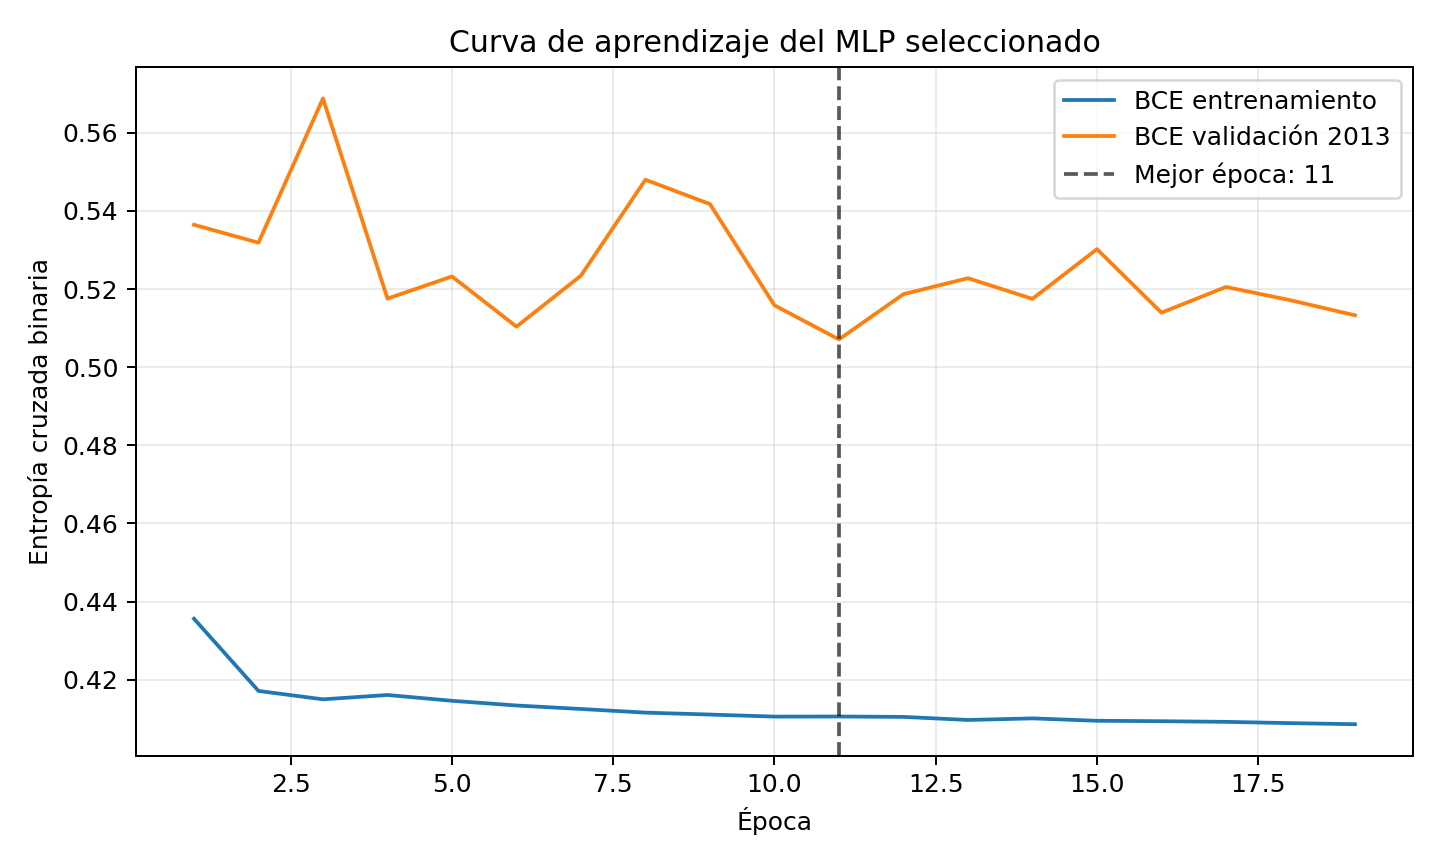

In [11]:
# Repite el ajuste final para registrar la curva de aprendizaje por época.
import yaml
OUT = ROOT / "reports" / "pd_hyperparameter_search"
TRIALS_CSV = OUT / "ensayos.csv"
final_config_path = ROOT / "configs" / "pd_mlp_best.yaml"
final_config = yaml.safe_load(final_config_path.read_text(encoding="utf-8"))
chosen_config = {k: final_config[k] for k in ["n_layers", "width", "activation", "optimizer", "learning_rate", "dropout", "reg_type", "l1", "l2", "batch_size"]}
final_seed = int(final_config["seed"])

def fit_with_history(config, seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    model = PDNet(X_train_np.shape[1], config["n_layers"], config["width"], config["activation"], config["dropout"]).to(DEVICE)
    optimizer = make_optimizer(model, config); loss_fn = nn.BCEWithLogitsLoss()
    loader = make_loader(X_train_np, y_train_np, config["batch_size"], seed)
    x_val_t = torch.from_numpy(X_val_np).to(DEVICE); y_val_t = torch.from_numpy(y_val_np).to(DEVICE)
    rows=[]; best_loss=float("inf"); best_state=None; best_epoch=0; stale=0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); total_bce=0.0; n_seen=0
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits=model(xb); bce=loss_fn(logits,yb)
            objective=bce+weight_penalty(model,config)
            if not torch.isfinite(objective): raise FloatingPointError("loss no finita en curva final")
            objective.backward(); optimizer.step()
            total_bce += float(bce.detach().cpu()) * len(yb); n_seen += len(yb)
        model.eval()
        with torch.no_grad(): val_bce=float(loss_fn(model(x_val_t),y_val_t).item())
        rows.append({"epoch":epoch,"train_bce":total_bce/n_seen,"validation_bce":val_bce})
        if val_bce < best_loss - 1e-5:
            best_loss=val_bce; best_epoch=epoch; stale=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE: break
    model.load_state_dict(best_state); model.to(DEVICE); model.eval()
    return model,pd.DataFrame(rows),best_epoch

learning_model, learning_history, best_epoch = fit_with_history(chosen_config, final_seed)
learning_history.to_csv(OUT / "curva_aprendizaje_final.csv", index=False)
fig,ax=plt.subplots(figsize=(8,4.8))
ax.plot(learning_history.epoch,learning_history.train_bce,label="BCE entrenamiento")
ax.plot(learning_history.epoch,learning_history.validation_bce,label="BCE validación 2013")
ax.axvline(best_epoch,color="black",linestyle="--",alpha=.65,label=f"Mejor época: {best_epoch}")
ax.set(xlabel="Época",ylabel="Entropía cruzada binaria",title="Curva de aprendizaje del MLP seleccionado")
ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUT / "curva_aprendizaje_final.png",dpi=180);plt.show()

trials_df=pd.read_csv(TRIALS_CSV)
robust_df=pd.read_csv(OUT / "robustez_semillas.csv")
def optional_csv(filename):
    path=OUT / filename
    return pd.read_csv(path) if path.exists() else pd.DataFrame()
preliminary_trials=pd.concat([optional_csv("ensayos_phase2_preliminar_descartada.csv"),
                              optional_csv("ensayos_phase2_20_previo_a_150_descartado.csv")],ignore_index=True)
preliminary_robust=pd.concat([optional_csv("robustez_preliminar_descartada.csv"),
                              optional_csv("robustez_previo_a_150_descartada.csv")],ignore_index=True)
preliminary_configs=[]
for filename in ["configuracion_preliminar_descartada.json","configuracion_previo_a_150_descartada.json"]:
    path=OUT / filename
    if path.exists(): preliminary_configs.append(json.loads(path.read_text(encoding="utf-8")))
official_seconds=float(trials_df.seconds.sum()+robust_df.seconds.sum()+final_config["validation_fit"]["seconds"])
preliminary_seconds=float(preliminary_trials.seconds.sum()+preliminary_robust.seconds.sum()+
                          sum(item.get("validation_fit",{}).get("seconds",0.0) for item in preliminary_configs))
summary={"phase1_trials":int((trials_df.phase=="phase1").sum()),
         "phase2_trials":int((trials_df.phase=="phase2").sum()),
         "successful_trials":int((trials_df.status=="ok").sum()),
         "failed_trials":int((trials_df.status!="ok").sum()),
         "superseded_discarded_trials":int(len(preliminary_trials)),
         "superseded_discarded_robustness_runs":int(len(preliminary_robust)),
         "phase1_search_seconds":float(trials_df.query("phase==\'phase1\'").seconds.sum()),
         "phase2_search_seconds":float(trials_df.query("phase==\'phase2\'").seconds.sum()),
         "search_seconds_total":float(trials_df.seconds.sum()),
         "robustness_seconds_total":float(robust_df.seconds.sum()),
         "official_compute_seconds":official_seconds,
         "preliminary_discarded_compute_seconds":preliminary_seconds,
         "total_compute_including_discarded":official_seconds+preliminary_seconds,
         "phase1_best_auc":float(trials_df.query("phase=='phase1'").auc.max()),
         "phase2_best_auc":float(trials_df.query("phase=='phase2'").auc.max()),
         "robustness_candidate_runs":int(len(robust_df)),
         "robustness_seeds_per_candidate":int(robust_df.groupby("candidate_id").seed.nunique().min()),
         "selected_robustness_mean_auc":float(final_config["robustness_mean_auc"]),
         "selected_robustness_std_auc":float(final_config["robustness_std_auc"]),
         "selected_validation_brier":float(final_config["validation_fit"]["brier"]),
         "selected_parameters":int(final_config["validation_fit"]["parameters"]),
         "selected_early_stopping_epoch":int(best_epoch),
         "test_used_for_selection":False,"supplementary_2015_used_for_selection":False,
         "final_test_and_logistic_comparison":"pendiente para la siguiente etapa"}
(OUT / "resumen_optimizacion.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")
print(json.dumps(summary,indent=2,ensure_ascii=False))


## 10. Brier y calibración en validación

Para el MLP seleccionado se calcula Brier en validación 2013 y se grafica la fracción observada de incumplimientos frente a la probabilidad media predicha por deciles. La diagonal representa calibración perfecta. Se evalúan probabilidades crudas; no se ajusta un calibrador con validación. Test 2014 queda reservado para la evaluación final.

$$\mathrm{Brier}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)^2.$$


<string>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
{
  "auc": 0.6730613455734047,
  "gini": 0.3461226911468094,
  "ks": 0.24847902549471979,
  "brier": 0.1658666687955863,
  "log_loss": 0.5071000728995737,
  "split": "validation_2013",
  "calibration_bins": 10,
  "calibrator_fitted": false
}
                bin     n  observed_default_rate  mean_predicted_pd
0  (0.00401, 0.121]  7320               0.071995           0.095817
1    (0.121, 0.147]  7319               0.114497           0.135385
2    (0.147, 0.167]  7319               0.144965           0.157562
3    (0.167, 0.184]  7320               0.169809           0.175573
4    (0.184, 0.201]  7319               0.212871           0.192446
5    (0.201, 0.219]  7319               0.228993           0.209436
6    (0.219, 0.241]  7320               0.262568           0.229246
7    (0.241, 0.278]  7319               0.297718           0.257745
8     (0.278, 0.35]  7319               0.348135           

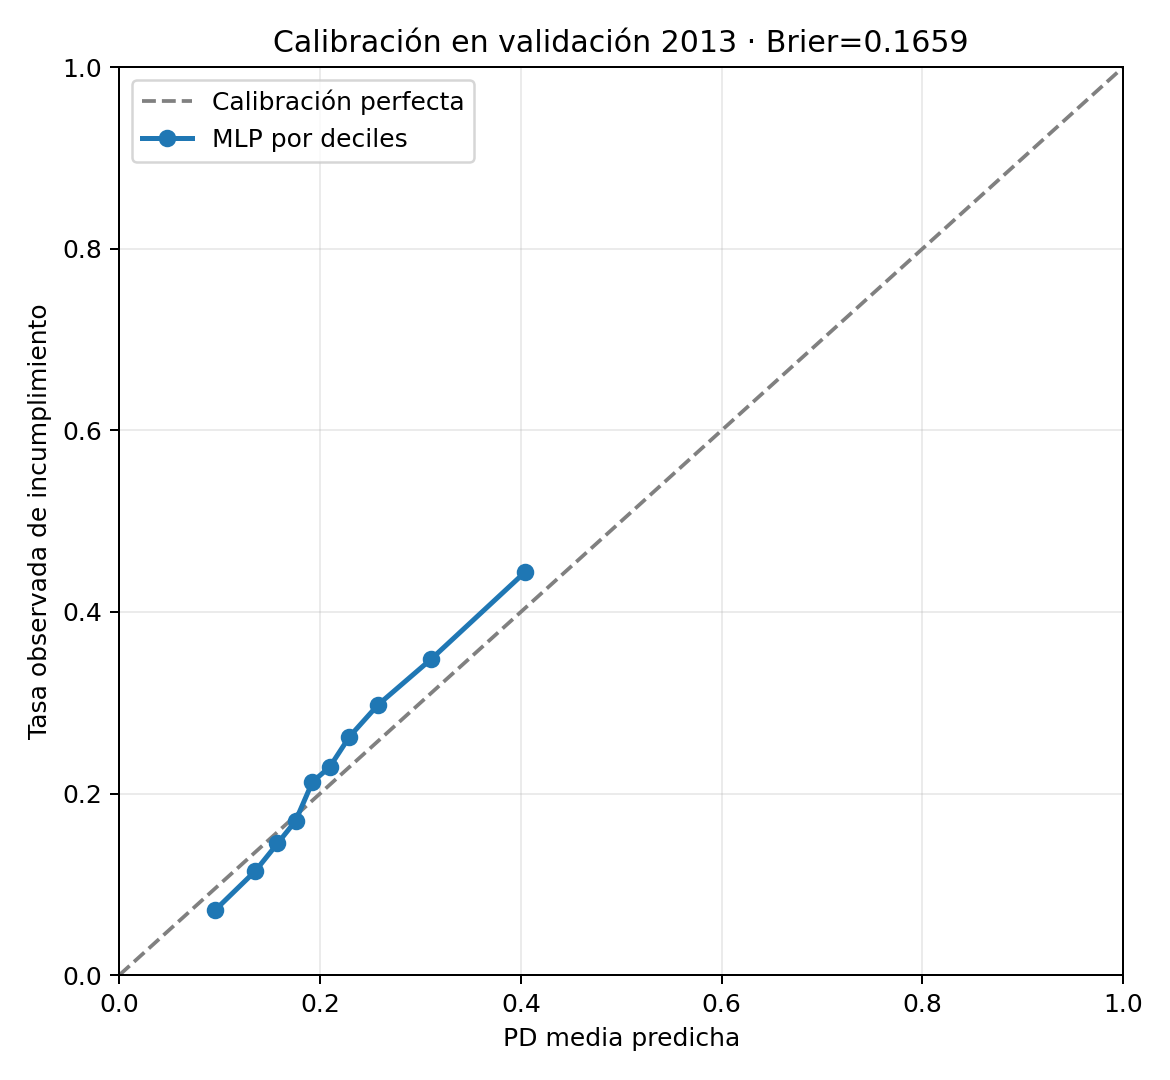

In [12]:
# Probabilidades del modelo seleccionado sobre validación 2013 únicamente.
x_val_t=torch.from_numpy(X_val_np).to(DEVICE)
learning_model.eval()
with torch.no_grad():
    validation_probability=torch.sigmoid(learning_model(x_val_t)).detach().cpu().numpy()
validation_metrics=binary_metrics(y_val_np,validation_probability)
observed_rate,mean_probability=calibration_curve(y_val_np,validation_probability,n_bins=10,strategy="quantile")
calibration_bins=pd.qcut(validation_probability,q=10,duplicates="drop")
calibration_table=(pd.DataFrame({"bin":calibration_bins,"y":y_val_np,"p":validation_probability})
                   .groupby("bin",observed=True).agg(n=("y","size"),observed_default_rate=("y","mean"),
                                                    mean_predicted_pd=("p","mean")).reset_index())
calibration_table.to_csv(OUT/"pd_calibracion_deciles_validacion.csv",index=False)
fig,ax=plt.subplots(figsize=(6.5,6.0))
ax.plot([0,1],[0,1],linestyle="--",color="gray",label="Calibración perfecta")
ax.plot(mean_probability,observed_rate,marker="o",linewidth=2,label="MLP por deciles")
ax.set(xlim=(0,1),ylim=(0,1),xlabel="PD media predicha",ylabel="Tasa observada de incumplimiento",
       title=f"Calibración en validación 2013 · Brier={validation_metrics['brier']:.4f}")
ax.grid(alpha=.25);ax.legend();fig.tight_layout()
calibration_plot=OUT/"pd_calibracion_validacion.png"
fig.savefig(calibration_plot,dpi=180);plt.show()
validation_metrics.update({"split":"validation_2013","calibration_bins":10,"calibrator_fitted":False})
(OUT/"pd_metricas_validacion.json").write_text(json.dumps(validation_metrics,indent=2,ensure_ascii=False),encoding="utf-8")
print(json.dumps(validation_metrics,indent=2,ensure_ascii=False))
display(calibration_table)


## 11. Conclusiones de la optimización

La búsqueda de 150 ensayos iniciales y 30 de refinamiento exploró un espacio amplio. El mejor AUC de fase 1 fue 0,6734 y el de fase 2 fue 0,6747: una mejora absoluta aproximada de 0,0013. Esta ganancia es pequeña frente a la variación observada entre semillas, por lo que no se justifica repetir ahora otra búsqueda del mismo tamaño sin revisar antes los datos y el protocolo. La estrategia de dos fases es razonable como exploración gruesa seguida de refinamiento, aunque en esta ejecución el refinamiento aportó poco.

La configuración seleccionada tiene dos capas ocultas de 64 neuronas y 7.105 parámetros. Su AUC medio en cinco semillas fue 0,6691 (desviación estándar 0,0024). Se prefirió una configuración más pequeña dentro del margen de variabilidad frente a una alternativa algo mayor con AUC medio ligeramente superior. Esto favorece parsimonia sin una pérdida de discriminación claramente establecida.

En validación 2013, el modelo obtuvo AUC 0,6731, Gini 0,3461, KS 0,2485, Brier 0,1659 y log-loss 0,5071. La tasa de incumplimiento de esa partición es 0,2295; una predicción constante con esa tasa tendría un Brier aproximado de 0,1768. El resultado del MLP mejora ese referente, pero la mejora de calibración es moderada. La curva por deciles sugiere sobreestimación en los grupos de riesgo más bajo y subestimación en varios grupos de mayor riesgo.

La pérdida de entrenamiento desciende mientras la de validación permanece más alta y fluctúa; su mínimo registrado ocurre cerca de la época 11. Esto es compatible con sobreajuste, pero también puede reflejar diferencias temporales entre entrenamiento 2007–2012 y validación 2013. La validación se utilizó para parada temprana y selección, de modo que sus métricas no son una estimación final independiente. La prueba de 2014 debe mantenerse reservada hasta congelar el modelo y las decisiones.

La búsqueda de hiperparámetros no reemplaza la comparación con la regresión logística ni las corridas finales requeridas por la evaluación. Si se exigen 30 semillas del modelo final, estas deben ejecutarse sobre la configuración ya fijada; las cinco semillas por candidata usadas aquí para robustez no equivalen a 30 corridas finales.

### Qué podría mejorar los resultados

1. **Investigar la brecha temporal antes de aumentar el número de ensayos.** Comparar entre entrenamiento y validación la tasa de incumplimiento, los faltantes, las categorías y las distribuciones de las variables. Así se puede evaluar si la brecha refleja sobreajuste, cambio de población o ambos.
2. **Ampliar el análisis exploratorio ya disponible.** Añadir tasas de incumplimiento por año, distribuciones de predictores por clase, faltantes por periodo y análisis de valores extremos sin eliminarlos automáticamente. La alta proporción de préstamos sin etiqueta hace importante describir qué préstamos sí tienen un resultado observado.



## 12. Referencias

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*(10), 281–305. https://jmlr.org/papers/v13/bergstra12a.html
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html
- Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *Advances in Neural Information Processing Systems, 34*. https://proceedings.neurips.cc/paper/2021/hash/9d86d83f925f2149e9edb0ac3b49229c-Abstract.html
- Kadra, A., Lindauer, M., Hutter, F., & Grabocka, J. (2021). Well-tuned simple nets excel on tabular datasets. *Advances in Neural Information Processing Systems, 34*. https://proceedings.neurips.cc/paper_files/paper/2021/file/c902b497eb972281fb5b4e206db38ee6-Paper.pdf
- Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2nd ed.). O’Reilly Media.

Para este trabajo son pertinentes los capítulos 2–4 (exploración y preparación de datos, evaluación y selección de modelos), el capítulo 10 (MLP y ajuste de hiperparámetros; especialmente pp. 294–326) y el capítulo 11 (optimizadores y regularización; especialmente pp. 351–371).
